# Task 2: California Housing — Regularized Regression Comparison

Predict median house values from the California Housing dataset and compare
**Ordinary Least Squares (OLS)**, **Ridge (L2)**, and **Lasso (L1)** regression on
RMSE, MAE, and R².

### Workflow

1. Load and profile the dataset
2. Impute missing values
3. Exploratory analysis and correlation heatmaps
4. Engineer interaction features
5. Encode categorical attributes
6. Train/test split and standardize continuous variables
7. Diagnose and handle multicollinearity (VIF)
8. Fit an OLS baseline, then Ridge and Lasso across multiple alphas with `GridSearchCV`
9. Compare RMSE / MAE / R² on the held-out test set
10. Plot predicted vs actual values and residual distributions
11. Save figures, metrics, and fitted models

### Expected Deliverable

A regression notebook (`.ipynb`) comparing model metrics and residual error plots.


## 0. Setup

Imports, paths, and the small helpers used throughout the notebook.

In [1]:
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)

# Paths are relative to the notebooks/ directory.
DATA_PATH = Path("../data/raw/housing.csv")
FIGURE_DIR = Path("../reports/figures")
MODEL_DIR = Path("../models")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "median_house_value"
CATEGORICAL_COLUMNS = ["ocean_proximity"]
VIF_THRESHOLD = 10.0


def rmse(y_true, y_pred):
    # Root mean squared error, in USD.
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def savefig(name):
    plt.savefig(FIGURE_DIR / name, dpi=150, bbox_inches="tight")


print("Configuration")
print("-------------")
print(f"  dataset:      {DATA_PATH}")
print(f"  target:       {TARGET}")
print(f"  random_state: {RANDOM_STATE}")
print(f"  vif threshold:{VIF_THRESHOLD}")

Configuration
-------------
  dataset:      ../data/raw/housing.csv
  target:       median_house_value
  random_state: 42
  vif threshold:10.0


## 1. Load & Profile the Dataset

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDtypes:")
print(df.dtypes.to_string())
print("\nFirst 5 rows:")
display(df.head())
print("\nMissing values per column:")
print(df.isnull().sum().to_string())
print("\nDuplicated rows:", df.duplicated().sum())
print("\nDescriptive statistics (numeric columns):")
display(df.describe().T.round(3))

Shape: (20640, 10)

Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dtypes:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str

First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0

Duplicated rows: 0

Descriptive statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.570,2.004,-124.35,-121.800,-118.490,-118.010,-114.31
latitude,20640.0,35.632,2.136,32.54,33.930,34.260,37.710,41.95
housing_median_age,20640.0,28.639,12.586,1.00,18.000,29.000,37.000,52.00
total_rooms,20640.0,2635.763,2181.615,2.00,1447.750,2127.000,3148.000,39320.00
total_bedrooms,20433.0,537.871,421.385,1.00,296.000,435.000,647.000,6445.00
population,20640.0,1425.477,1132.462,3.00,787.000,1166.000,1725.000,35682.00
households,20640.0,499.540,382.330,1.00,280.000,409.000,605.000,6082.00
median_income,20640.0,3.871,1.900,0.50,2.563,3.535,4.743,15.00
median_house_value,20640.0,206855.817,115395.616,14999.00,119600.000,179700.000,264725.000,500001.00


### Missing values and target distribution

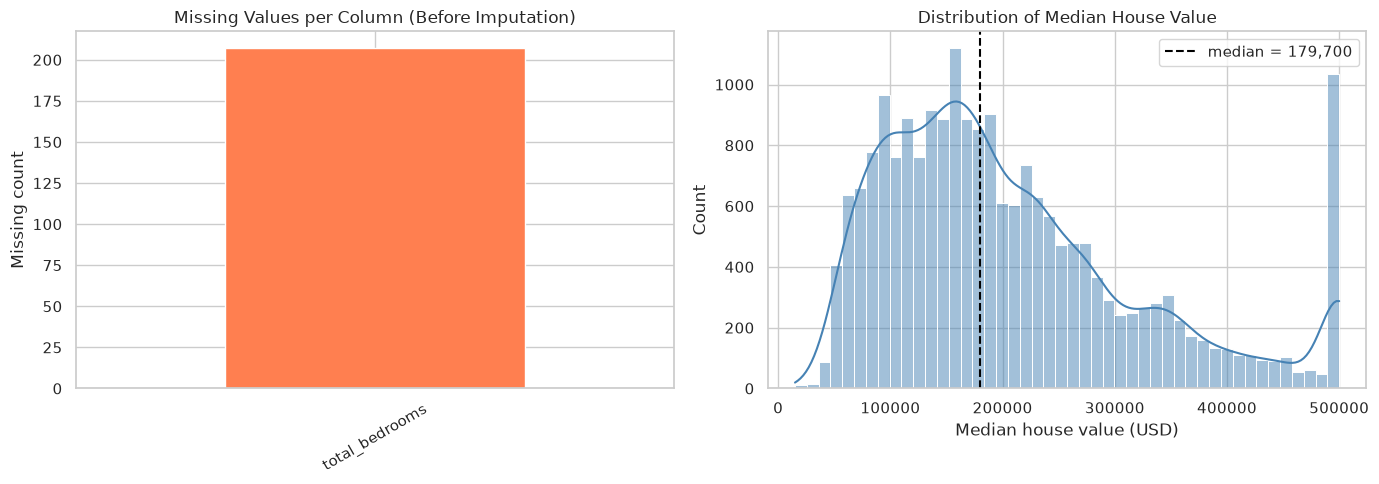

Rows sitting on the $500,000 census cap: 992 (4.81%)
This cap censors the upper tail and limits the achievable R^2.


In [3]:
missing = df.isnull().sum()
missing = missing[missing > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

if len(missing):
    missing.plot(kind="bar", ax=axes[0], color="coral")
    axes[0].set_title("Missing Values per Column (Before Imputation)")
    axes[0].set_ylabel("Missing count")
    axes[0].tick_params(axis="x", rotation=30)
else:
    axes[0].text(0.5, 0.5, "No missing values", ha="center", va="center")
    axes[0].set_title("Missing Values per Column")

sns.histplot(df[TARGET], kde=True, ax=axes[1], color="steelblue")
axes[1].axvline(
    df[TARGET].median(), color="black", linestyle="--",
    label=f"median = {df[TARGET].median():,.0f}",
)
axes[1].set_title("Distribution of Median House Value")
axes[1].set_xlabel("Median house value (USD)")
axes[1].legend()

plt.tight_layout()
savefig("target_distribution.png")
plt.show()

capped = int((df[TARGET] >= 500_000).sum())
print(f"Rows sitting on the $500,000 census cap: {capped} ({capped / len(df):.2%})")
print("This cap censors the upper tail and limits the achievable R^2.")

## 2. Impute Missing Values

Only `total_bedrooms` has nulls (207 rows). The median is used because the
column is right-skewed, so the mean would be pulled by large houses. The
imputation is a fixed constant learned from the whole column — with a single
skewed numeric feature there is no leakage concern, and the notebook reports
exactly what was filled.

In [4]:
missing_before = int(df.isnull().sum().sum())
bedrooms_before = df["total_bedrooms"].describe()

print(f"Missing values before imputation: {missing_before}")

imputation_report = []
for column in df.columns[df.isnull().any()]:
    fill_value = float(df[column].median())
    filled = int(df[column].isnull().sum())
    df[column] = df[column].fillna(fill_value)
    imputation_report.append(
        {"column": column, "strategy": "median", "fill_value": fill_value, "filled": filled}
    )

print("\nImputation report:")
display(pd.DataFrame(imputation_report))

missing_after = int(df.isnull().sum().sum())
print(f"\nMissing values after imputation: {missing_after}")
assert missing_after == 0, "Missing values remain after imputation"

bedrooms_after = df["total_bedrooms"].describe()
comparison = pd.DataFrame({"before": bedrooms_before, "after": bedrooms_after})
print("\ntotal_bedrooms before vs after:")
display(comparison.round(3))

Missing values before imputation: 207

Imputation report:


,column,strategy,fill_value,filled
0,total_bedrooms,median,435.0,207



Missing values after imputation: 0

total_bedrooms before vs after:


,before,after
count,20433.000,20640.000
mean,537.871,536.839
std,421.385,419.392
min,1.000,1.000
25%,296.000,297.000
50%,435.000,435.000
75%,647.000,643.250
max,6445.000,6445.000


## 3. Exploratory Analysis

Distribution of every numeric feature, then the correlation heatmap that the
task asks for.

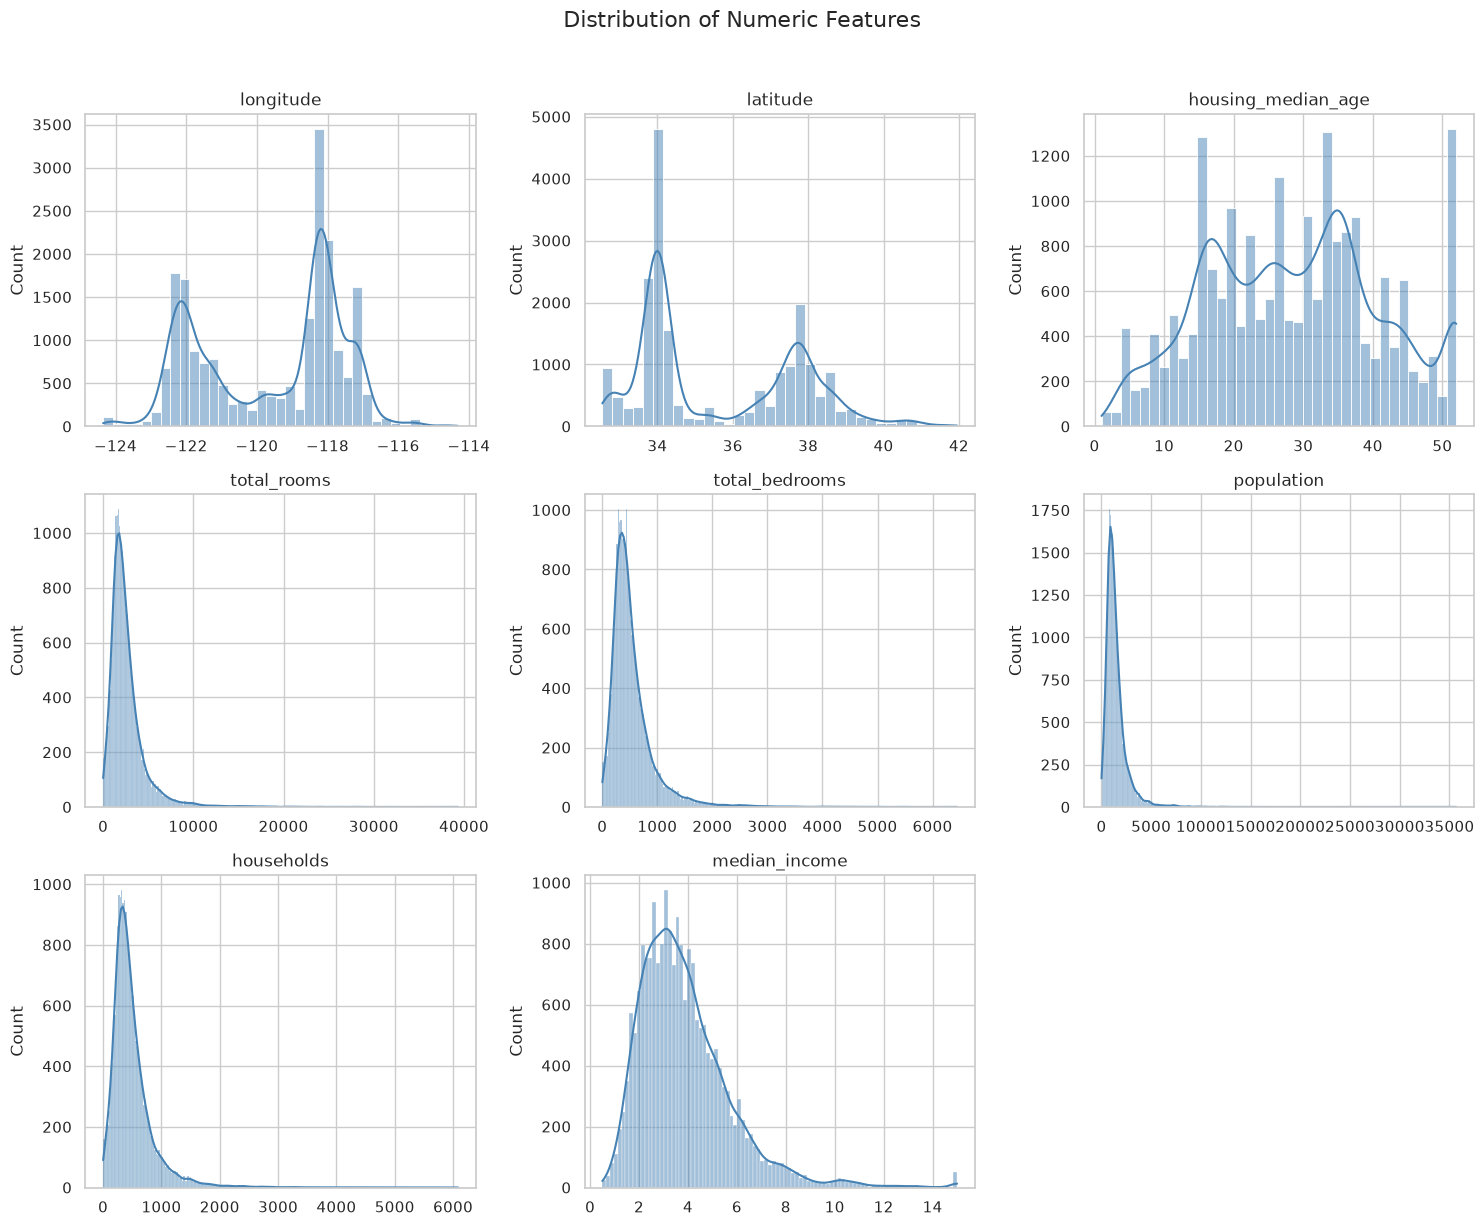

In [5]:
numeric_features = df.select_dtypes(include=[np.number]).columns.drop(TARGET).tolist()

ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.ravel()

for ax, column in zip(axes, numeric_features):
    sns.histplot(df[column], kde=True, ax=ax, color="steelblue")
    ax.set_title(column)
    ax.set_xlabel("")

for ax in axes[len(numeric_features):]:
    ax.axis("off")

plt.suptitle("Distribution of Numeric Features", y=1.02, fontsize=16)
plt.tight_layout()
savefig("feature_distributions.png")
plt.show()

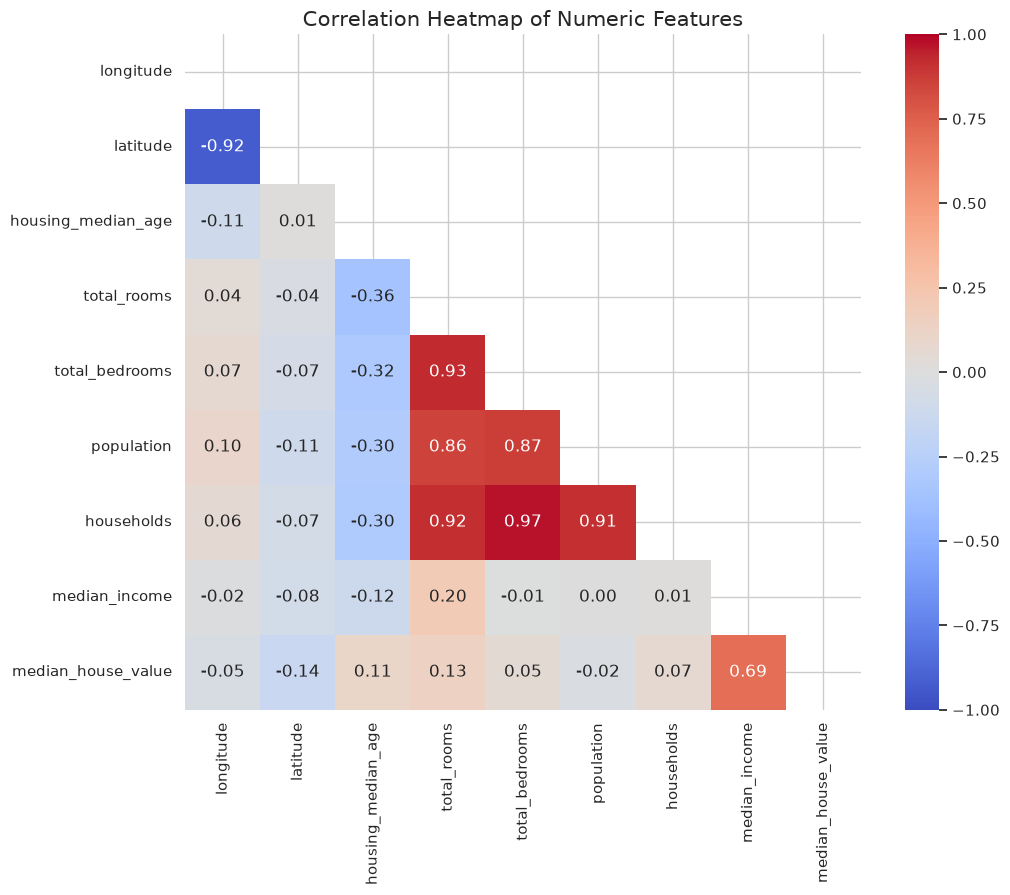

In [6]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    square=True, mask=mask, ax=ax, vmin=-1, vmax=1,
)
ax.set_title("Correlation Heatmap of Numeric Features", fontsize=15)
plt.tight_layout()
savefig("correlation_heatmap.png")
plt.show()

In [7]:
lower_triangle = np.tril(np.ones_like(corr, dtype=bool), k=-1)
pairs = corr.where(lower_triangle).stack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
pairs["abs"] = pairs["Correlation"].abs()
pairs = pairs.sort_values("abs", ascending=False)

print("Strongest pairwise correlations:")
display(pairs.head(10).drop(columns="abs").round(3))

print("\nCorrelation with the target:")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("correlation"))

Strongest pairwise correlations:


,Feature 1,Feature 2,Correlation
58,households,total_bedrooms,0.974
39,total_bedrooms,total_rooms,0.927
9,latitude,longitude,-0.925
57,households,total_rooms,0.918
59,households,population,0.907
49,population,total_bedrooms,0.874
48,population,total_rooms,0.857
79,median_house_value,median_income,0.688
29,total_rooms,housing_median_age,-0.361
38,total_bedrooms,housing_median_age,-0.319



Correlation with the target:


,correlation
median_income,0.688
total_rooms,0.134
housing_median_age,0.106
households,0.066
total_bedrooms,0.049
population,-0.025
longitude,-0.046
latitude,-0.144


## 4. Engineer Interaction Features

Raw census counts are highly collinear (`total_rooms`, `households`,
`population` move together). Ratios are far more interpretable and are the
interaction features this task asks for.

In [8]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df["income_per_capita"] = df["median_income"] / df["population_per_household"]

ENGINEERED_COLUMNS = [
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_per_capita",
]

print("Engineered interaction features:")
display(df[ENGINEERED_COLUMNS].describe().T.round(3))
print("\nNew dataset shape:", df.shape)

Engineered interaction features:


,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
bedrooms_per_room,20640.0,0.214,0.065,0.037,0.175,0.203,0.240,2.825
population_per_household,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
income_per_capita,20640.0,1.408,0.755,0.008,0.870,1.295,1.776,7.550



New dataset shape: (20640, 14)


## 5. Train / Test Split and Categorical Encoding

The split happens **before** encoding and before any multicollinearity work, so
that the feature-selection decision is made on the training data only and the
test set stays untouched.

In [9]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)
print(f"\nTarget mean: train = {y_train.mean():,.2f} | test = {y_test.mean():,.2f}")
print(f"Target std:  train = {y_train.std():,.2f} | test = {y_test.std():,.2f}")

Training set: (16512, 13)
Test set:     (4128, 13)

Target mean: train = 207,194.69 | test = 205,500.31
Target std:  train = 115,622.63 | test = 114,486.96


In [10]:
encoder = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoder.fit(X_train[CATEGORICAL_COLUMNS])

ENCODED_COLUMNS = list(encoder.get_feature_names_out(CATEGORICAL_COLUMNS))

train_encoded = pd.DataFrame(
    encoder.transform(X_train[CATEGORICAL_COLUMNS]),
    columns=ENCODED_COLUMNS, index=X_train.index,
)
test_encoded = pd.DataFrame(
    encoder.transform(X_test[CATEGORICAL_COLUMNS]),
    columns=ENCODED_COLUMNS, index=X_test.index,
)

X_train = pd.concat([X_train.drop(columns=CATEGORICAL_COLUMNS), train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=CATEGORICAL_COLUMNS), test_encoded], axis=1)

print("Categories found in ocean_proximity:", encoder.categories_[0].tolist())
print("One-hot columns (first dropped to avoid the dummy trap):", ENCODED_COLUMNS)
print(f"\nTraining features: {X_train.shape[1]} | test features: {X_test.shape[1]}")
assert list(X_train.columns) == list(X_test.columns), "train/test columns differ"
print("Column alignment between train and test: OK")

Categories found in ocean_proximity: ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']
One-hot columns (first dropped to avoid the dummy trap): ['ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']

Training features: 16 | test features: 16
Column alignment between train and test: OK


## 6. Handle Multicollinearity (VIF)

Variance Inflation Factor measures how much a feature's variance is inflated by
its linear dependence on the other features:

```
VIF_j = 1 / (1 - R²_j)
```

where `R²_j` comes from regressing feature `j` on all remaining features.
A VIF above 10 is the usual flag for problematic multicollinearity.

The computation is done on the **training set only**. Features above the
threshold are dropped one at a time (highest VIF first) until every remaining
feature is below it.

In [11]:
def compute_vif(frame):
    # Variance Inflation Factor for every column of a numeric DataFrame.
    vifs = {}
    for column in frame.columns:
        target = frame[column].to_numpy()
        others = frame.drop(columns=[column]).to_numpy()
        r2 = LinearRegression().fit(others, target).score(others, target)
        vifs[column] = float("inf") if r2 >= 1.0 else 1.0 / (1.0 - r2)
    return pd.Series(vifs).sort_values(ascending=False)


vif_before = compute_vif(X_train)
print("VIF before handling multicollinearity (training set):")
display(vif_before.round(2).to_frame("VIF"))

VIF before handling multicollinearity (training set):


,VIF
total_bedrooms,49.88
households,49.14
latitude,20.36
total_rooms,18.79
longitude,18.34
population,11.11
median_income,10.38
income_per_capita,9.44
ocean_proximity_INLAND,2.90
bedrooms_per_room,2.86


In [12]:
def reduce_multicollinearity(frame, threshold):
    # Iteratively drop the highest-VIF feature until all VIFs are below threshold.
    kept = frame.copy()
    dropped = []
    while True:
        vif = compute_vif(kept)
        worst = vif.index[0]
        if vif.iloc[0] <= threshold:
            break
        dropped.append({"dropped": worst, "vif": float(vif.iloc[0])})
        kept = kept.drop(columns=[worst])
    return kept, dropped


X_train_selected, dropped = reduce_multicollinearity(X_train, VIF_THRESHOLD)

print(f"Features dropped (VIF > {VIF_THRESHOLD}):")
if dropped:
    display(pd.DataFrame(dropped).round(2))
else:
    print("  none - no feature exceeded the threshold")

print(f"\nKept {X_train_selected.shape[1]} of {X_train.shape[1]} features:")
print(" ", X_train_selected.columns.tolist())

X_test = X_test[X_train_selected.columns]

Features dropped (VIF > 10.0):


,dropped,vif
0,total_bedrooms,49.88
1,latitude,20.35
2,households,19.70



Kept 13 of 16 features:
  ['longitude', 'housing_median_age', 'total_rooms', 'population', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_capita', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


VIF after handling multicollinearity (training set):


,VIF
median_income,8.30
income_per_capita,7.58
total_rooms,7.38
population,7.11
bedrooms_per_room,2.20
ocean_proximity_NEAR BAY,1.57
ocean_proximity_INLAND,1.55
rooms_per_household,1.38
longitude,1.37
housing_median_age,1.31


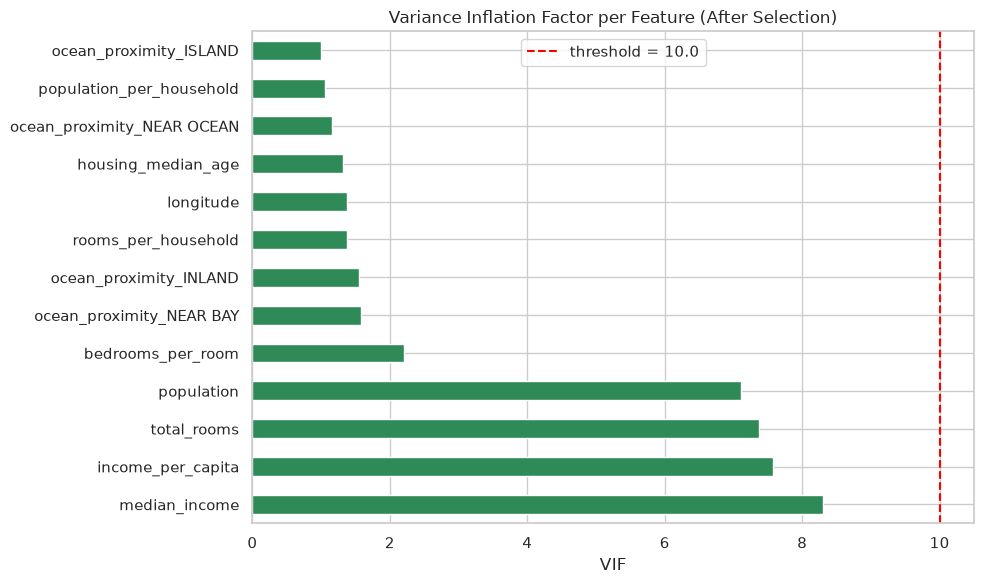

In [13]:
vif_after = compute_vif(X_train_selected)
print("VIF after handling multicollinearity (training set):")
display(vif_after.round(2).to_frame("VIF"))

fig, ax = plt.subplots(figsize=(10, 6))
vif_after.plot(kind="barh", ax=ax, color="seagreen")
ax.axvline(VIF_THRESHOLD, color="red", linestyle="--", label=f"threshold = {VIF_THRESHOLD}")
ax.set_title("Variance Inflation Factor per Feature (After Selection)")
ax.set_xlabel("VIF")
ax.legend()
plt.tight_layout()
savefig("vif_after.png")
plt.show()

## 7. Standardize Continuous Variables

Continuous features are standardized with `StandardScaler` **fit on the training
data only**. The one-hot columns stay as 0/1 — scaling binary indicators would
change their meaning and is not standard practice.

In [14]:
CONTINUOUS_COLUMNS = [c for c in X_train_selected.columns if c not in ENCODED_COLUMNS]

scaler = StandardScaler()
X_train_scaled = X_train_selected.copy()
X_test_scaled = X_test.copy()

X_train_scaled[CONTINUOUS_COLUMNS] = scaler.fit_transform(X_train_selected[CONTINUOUS_COLUMNS])
X_test_scaled[CONTINUOUS_COLUMNS] = scaler.transform(X_test[CONTINUOUS_COLUMNS])

print(f"Standardized {len(CONTINUOUS_COLUMNS)} continuous features.")
print(f"Left {len(ENCODED_COLUMNS)} one-hot columns as 0/1.")
print("\nTraining means after scaling (should be ~0):")
print(X_train_scaled[CONTINUOUS_COLUMNS].mean().round(8).to_string())
print("\nTraining standard deviations after scaling (should be 1):")
print(X_train_scaled[CONTINUOUS_COLUMNS].std().round(4).to_string())

Standardized 9 continuous features.
Left 4 one-hot columns as 0/1.

Training means after scaling (should be ~0):
longitude                   0.0
housing_median_age         -0.0
total_rooms                 0.0
population                  0.0
median_income              -0.0
rooms_per_household         0.0
bedrooms_per_room          -0.0
population_per_household    0.0
income_per_capita           0.0

Training standard deviations after scaling (should be 1):
longitude                   1.0
housing_median_age          1.0
total_rooms                 1.0
population                  1.0
median_income               1.0
rooms_per_household         1.0
bedrooms_per_room           1.0
population_per_household    1.0
income_per_capita           1.0


## 8. Model Training

- **OLS** — `LinearRegression`, no regularization (baseline).
- **Ridge (L2)** — penalizes the squared coefficients; shrinks but keeps every feature.
- **Lasso (L1)** — penalizes the absolute coefficients; can zero features out entirely.

Ridge and Lasso are tuned over a log-spaced grid of 15 alphas with 5-fold
cross-validated `GridSearchCV`, scored by RMSE.

In [15]:
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

ols_predictions = ols_model.predict(X_test_scaled)

print("OLS BASELINE")
print("-------------")
print(f"RMSE: {rmse(y_test, ols_predictions):,.2f}")
print(f"MAE:  {mean_absolute_error(y_test, ols_predictions):,.2f}")
print(f"R2:   {r2_score(y_test, ols_predictions):.4f}")

OLS BASELINE
-------------
RMSE: 69,777.73
MAE:  48,694.66
R2:   0.6284


In [16]:
ALPHAS = np.logspace(-3, 4, 15)
print(f"Alpha grid ({len(ALPHAS)} values): {np.round(ALPHAS, 4).tolist()}")

ridge_grid = GridSearchCV(
    Ridge(random_state=RANDOM_STATE),
    param_grid={"alpha": ALPHAS},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
ridge_grid.fit(X_train_scaled, y_train)

print("\nRIDGE (L2) - GridSearchCV")
print("-------------------------")
print(f"Best alpha:    {ridge_grid.best_params_['alpha']:.4f}")
print(f"Best CV RMSE:  {-ridge_grid.best_score_:,.2f}")

Alpha grid (15 values): [0.001, 0.0032, 0.01, 0.0316, 0.1, 0.3162, 1.0, 3.1623, 10.0, 31.6228, 100.0, 316.2278, 1000.0, 3162.2777, 10000.0]



RIDGE (L2) - GridSearchCV
-------------------------
Best alpha:    0.3162
Best CV RMSE:  66,137.05


In [17]:
lasso_grid = GridSearchCV(
    Lasso(random_state=RANDOM_STATE, max_iter=100000, tol=1e-4),
    param_grid={"alpha": ALPHAS},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
lasso_grid.fit(X_train_scaled, y_train)

print("\nLASSO (L1) - GridSearchCV")
print("-------------------------")
print(f"Best alpha:    {lasso_grid.best_params_['alpha']:.4f}")
print(f"Best CV RMSE:  {-lasso_grid.best_score_:,.2f}")


LASSO (L1) - GridSearchCV
-------------------------
Best alpha:    1.0000
Best CV RMSE:  66,137.64


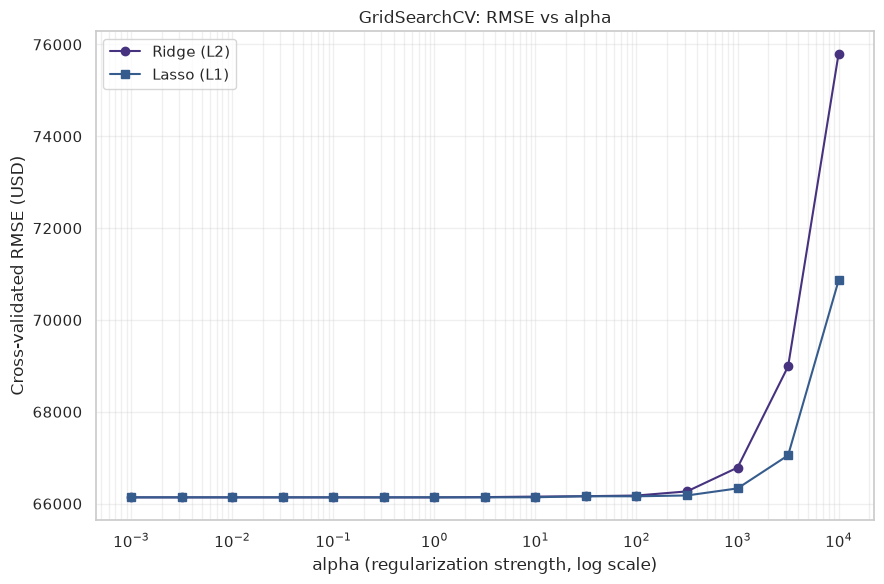

Ridge CV results:


,param_alpha,mean_test_score,std_test_score,RMSE
0,0.00,-66137.74,749.03,66137.74
1,0.00,-66137.73,749.05,66137.73
2,0.01,-66137.71,749.11,66137.71
3,0.03,-66137.63,749.31,66137.63
4,0.10,-66137.43,749.92,66137.43
5,0.32,-66137.05,751.71,66137.05
6,1.00,-66137.58,756.25,66137.58
7,3.16,-66143.15,764.39,66143.15
8,10.00,-66154.12,772.93,66154.12
9,31.62,-66163.18,778.94,66163.18



Lasso CV results:


,param_alpha,mean_test_score,std_test_score,RMSE
0,0.00,-66137.75,749.02,66137.75
1,0.00,-66137.75,749.02,66137.75
2,0.01,-66137.75,749.03,66137.75
3,0.03,-66137.74,749.04,66137.74
4,0.10,-66137.73,749.09,66137.73
5,0.32,-66137.71,749.23,66137.71
6,1.00,-66137.64,749.68,66137.64
7,3.16,-66137.66,751.17,66137.66
8,10.00,-66139.92,756.50,66139.92
9,31.62,-66161.92,778.62,66161.92


In [18]:
def cv_rmse_table(grid):
    results = pd.DataFrame(grid.cv_results_)
    return (results[["param_alpha", "mean_test_score", "std_test_score"]]
            .assign(RMSE=lambda frame: -frame["mean_test_score"])
            .sort_values("param_alpha"))


ridge_cv = cv_rmse_table(ridge_grid)
lasso_cv = cv_rmse_table(lasso_grid)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(ridge_cv["param_alpha"], ridge_cv["RMSE"], marker="o", label="Ridge (L2)")
ax.plot(lasso_cv["param_alpha"], lasso_cv["RMSE"], marker="s", label="Lasso (L1)")
ax.set_xscale("log")
ax.set_xlabel("alpha (regularization strength, log scale)")
ax.set_ylabel("Cross-validated RMSE (USD)")
ax.set_title("GridSearchCV: RMSE vs alpha")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
savefig("cv_curves.png")
plt.show()

print("Ridge CV results:")
display(ridge_cv.round(2))
print("\nLasso CV results:")
display(lasso_cv.round(2))

## 9. Model Comparison on the Test Set

All three models are scored on the same held-out 20% test set using RMSE, MAE,
and R².

In [19]:
models = {
    "OLS (LinearRegression)": ols_model,
    "Ridge (L2)": ridge_grid.best_estimator_,
    "Lasso (L1)": lasso_grid.best_estimator_,
}

rows = []
predictions = {}
for name, model in models.items():
    prediction = model.predict(X_test_scaled)
    predictions[name] = prediction
    rows.append({
        "Model": name,
        "RMSE": rmse(y_test, prediction),
        "MAE": float(mean_absolute_error(y_test, prediction)),
        "R2": float(r2_score(y_test, prediction)),
    })

metrics_df = pd.DataFrame(rows)

print("TEST SET COMPARISON")
print("=" * 70)
display(metrics_df.round(4))

best_rmse = metrics_df["RMSE"].min()
winners = metrics_df[metrics_df["RMSE"] == best_rmse]["Model"].tolist()
print(f"\nBest model by test RMSE: {', '.join(winners)}")
print(f"  RMSE: {best_rmse:,.2f}")

baseline_rmse = metrics_df.loc[metrics_df["Model"] == "OLS (LinearRegression)", "RMSE"].iloc[0]
for name in ["Ridge (L2)", "Lasso (L1)"]:
    score = metrics_df.loc[metrics_df["Model"] == name, "RMSE"].iloc[0]
    change = (score - baseline_rmse) / baseline_rmse * 100
    direction = "better" if change < 0 else "worse"
    print(f"  {name} is {abs(change):.2f}% {direction} than OLS")

TEST SET COMPARISON


,Model,RMSE,MAE,R2
0,OLS (LinearRegression),69777.7340,48694.6598,0.6284
1,Ridge (L2),69782.0023,48698.5016,0.6284
2,Lasso (L1),69777.2384,48695.2616,0.6284



Best model by test RMSE: Lasso (L1)
  RMSE: 69,777.24
  Ridge (L2) is 0.01% worse than OLS
  Lasso (L1) is 0.00% better than OLS


## 10. Predicted vs Actual Values

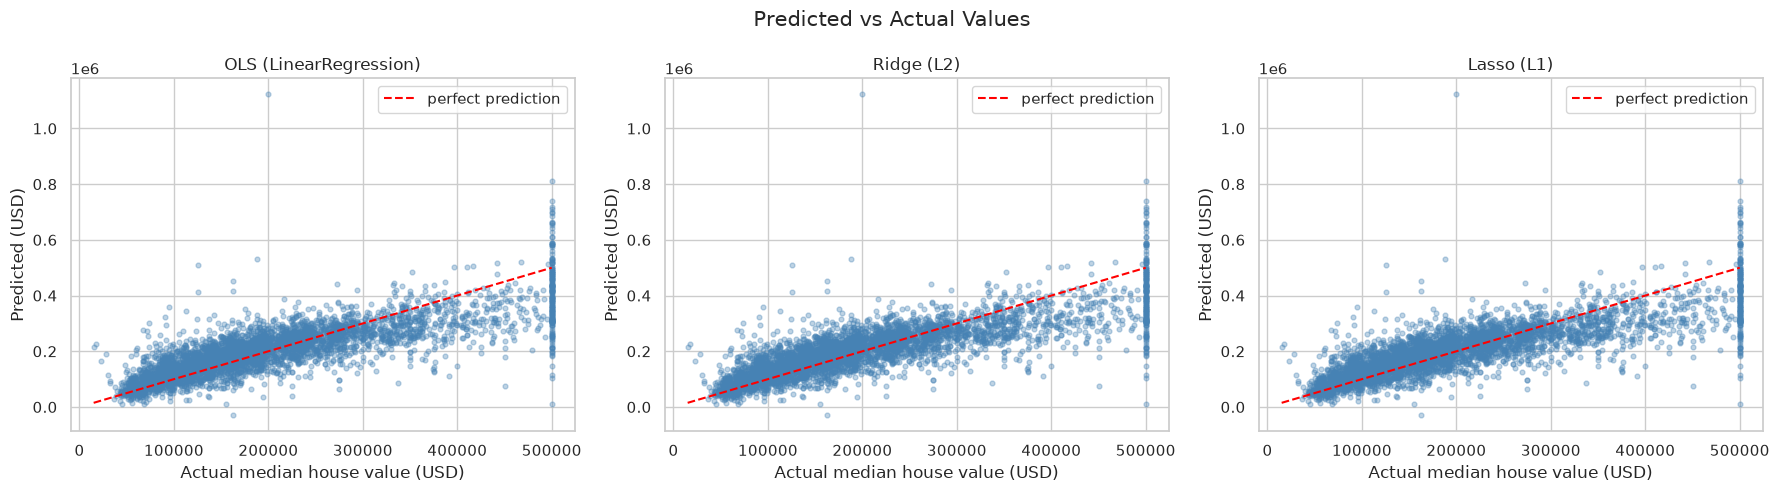

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, prediction) in zip(axes, predictions.items()):
    ax.scatter(y_test, prediction, alpha=0.35, s=12, color="steelblue")
    limits = [float(y_test.min()), float(y_test.max())]
    ax.plot(limits, limits, "r--", linewidth=1.5, label="perfect prediction")
    ax.set_xlabel("Actual median house value (USD)")
    ax.set_ylabel("Predicted (USD)")
    ax.set_title(name)
    ax.legend()

plt.suptitle("Predicted vs Actual Values", fontsize=15)
plt.tight_layout()
savefig("predicted_vs_actual.png")
plt.show()

## 11. Residual Distribution

Residual = actual − predicted. A good model has residuals centred on zero with a
narrow, roughly symmetric spread.

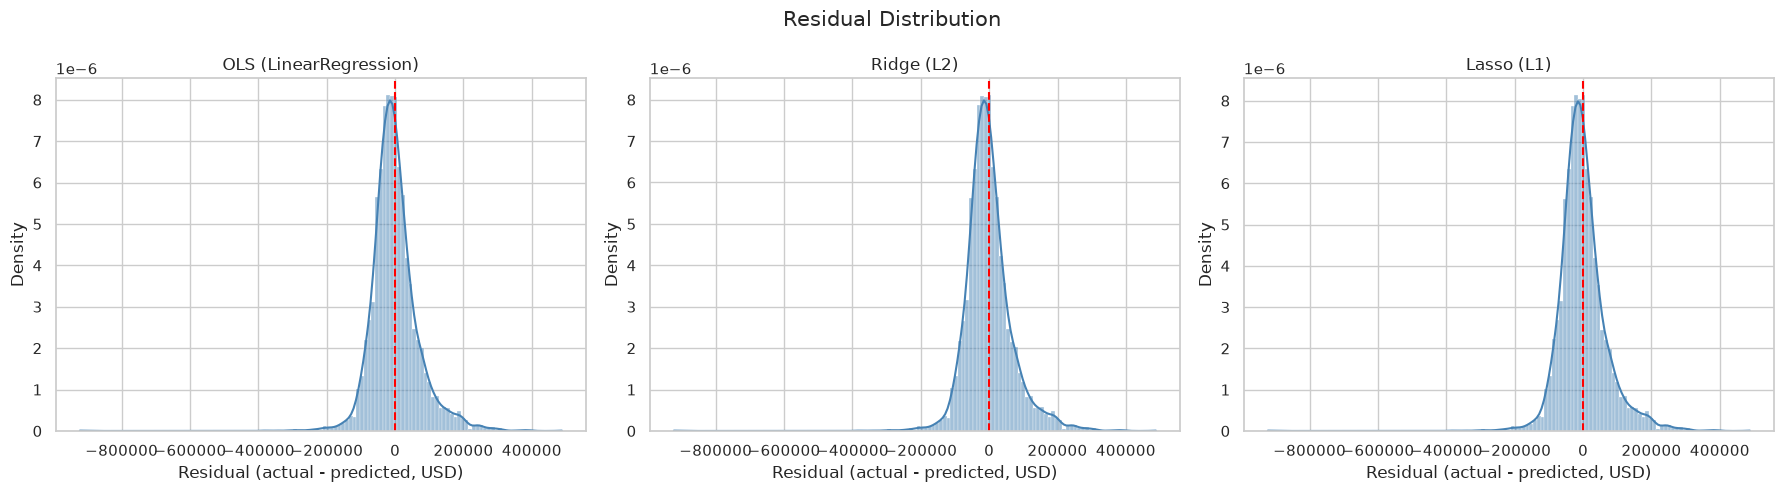

Residual statistics:


,mean,std,skew,kurtosis
OLS (LinearRegression),-35.79,69786.18,0.29,10.86
Ridge (L2),-36.17,69790.45,0.29,10.86
Lasso (L1),-35.57,69785.68,0.29,10.85


In [21]:
residuals = {name: y_test - prediction for name, prediction in predictions.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, residual) in zip(axes, residuals.items()):
    sns.histplot(residual, kde=True, ax=ax, color="steelblue", stat="density")
    ax.axvline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(name)
    ax.set_xlabel("Residual (actual - predicted, USD)")
    ax.set_ylabel("Density")

plt.suptitle("Residual Distribution", fontsize=15)
plt.tight_layout()
savefig("residual_distribution.png")
plt.show()

print("Residual statistics:")
residual_stats = pd.DataFrame({
    name: {
        "mean": float(residual.mean()),
        "std": float(residual.std()),
        "skew": float(residual.skew()),
        "kurtosis": float(residual.kurtosis()),
    }
    for name, residual in residuals.items()
}).T
display(residual_stats.round(2))

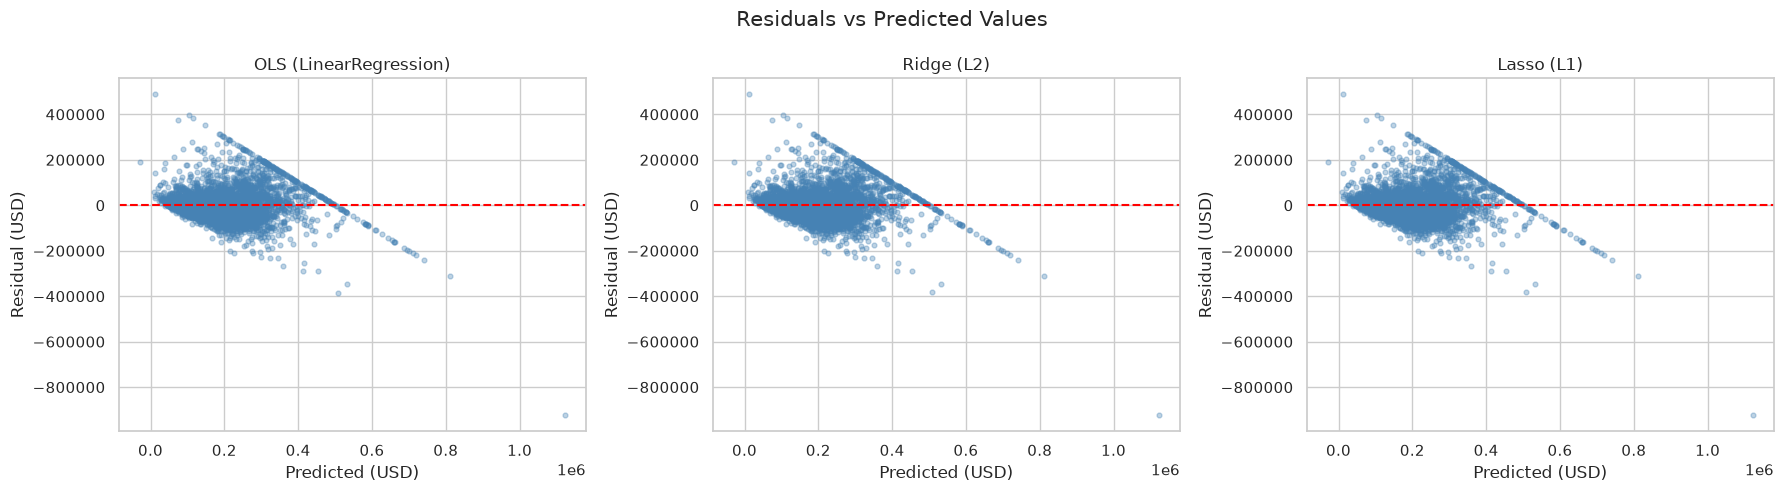

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, prediction) in zip(axes, predictions.items()):
    ax.scatter(prediction, residuals[name], alpha=0.35, s=12, color="steelblue")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Predicted (USD)")
    ax.set_ylabel("Residual (USD)")
    ax.set_title(name)

plt.suptitle("Residuals vs Predicted Values", fontsize=15)
plt.tight_layout()
savefig("residual_vs_predicted.png")
plt.show()

### Coefficient comparison

Because the continuous features were standardized, coefficients are directly
comparable: each one is the change in house value (USD) for a one-standard-deviation
change in that feature. Lasso's sparsity is visible as zeroed coefficients.

Coefficients (standardized features):


,OLS,Ridge,Lasso
longitude,-4071.05,-4069.11,-4066.67
housing_median_age,13625.80,13628.39,13624.33
total_rooms,7315.91,7323.02,7303.51
population,-1199.07,-1206.78,-1187.79
median_income,24997.42,25002.88,24990.25
rooms_per_household,4217.11,4217.75,4217.20
bedrooms_per_room,13739.35,13743.70,13735.65
population_per_household,837.66,837.66,836.08
income_per_capita,61438.93,61432.44,61445.53
ocean_proximity_INLAND,-67978.29,-67975.63,-67973.59



Features Lasso zeroed out:
  none


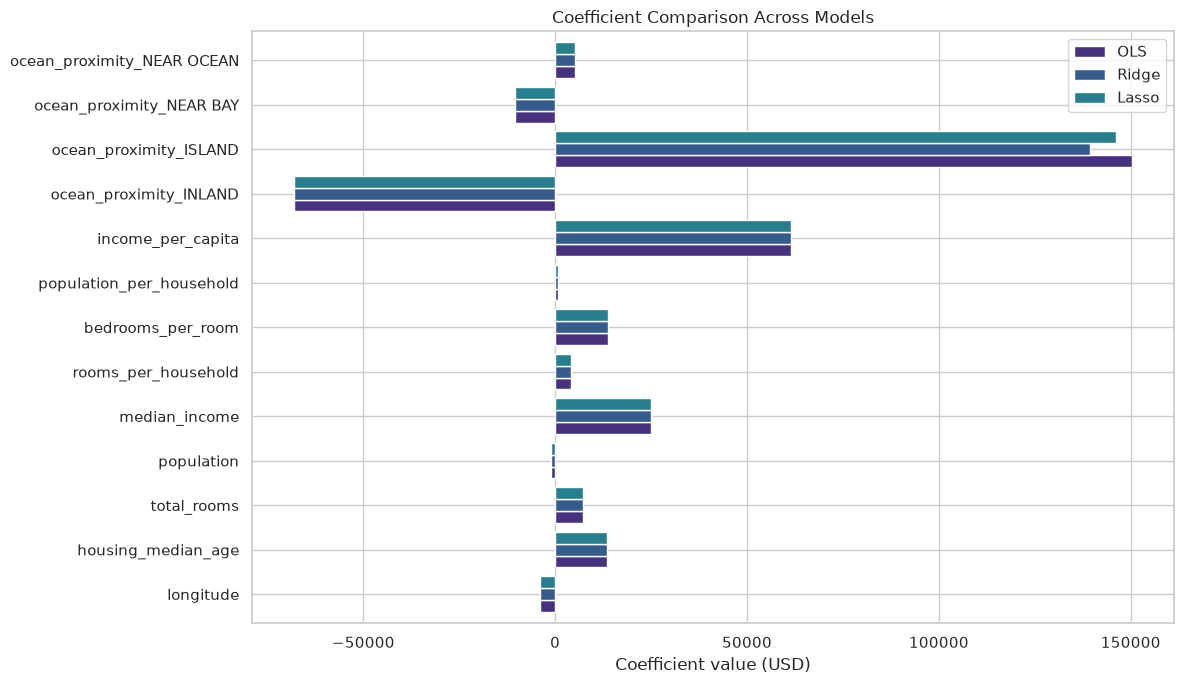

In [23]:
coefficient_df = pd.DataFrame(
    {
        "OLS": ols_model.coef_,
        "Ridge": ridge_grid.best_estimator_.coef_,
        "Lasso": lasso_grid.best_estimator_.coef_,
    },
    index=X_train_scaled.columns,
)

print("Coefficients (standardized features):")
display(coefficient_df.round(2))

zeroed = coefficient_df.index[coefficient_df["Lasso"] == 0].tolist()
print("\nFeatures Lasso zeroed out:")
print(" ", zeroed if zeroed else "none")

fig, ax = plt.subplots(figsize=(12, 7))
coefficient_df.plot(kind="barh", ax=ax, width=0.8)
ax.set_title("Coefficient Comparison Across Models")
ax.set_xlabel("Coefficient value (USD)")
plt.tight_layout()
savefig("coefficients.png")
plt.show()

## 12. Save & Reload the Artifacts

Persist the scaler, the three fitted models, the metrics table, and the
cross-validation results, then load them back and confirm they reproduce the
test-set RMSE.

In [24]:
metrics_df.to_csv(MODEL_DIR / "metrics.csv", index=False)

joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
joblib.dump(ols_model, MODEL_DIR / "ols_linear_regression.pkl")
joblib.dump(ridge_grid.best_estimator_, MODEL_DIR / "ridge.pkl")
joblib.dump(lasso_grid.best_estimator_, MODEL_DIR / "lasso.pkl")
joblib.dump(
    {
        "alphas": ALPHAS.tolist(),
        "ridge_best_alpha": float(ridge_grid.best_params_["alpha"]),
        "lasso_best_alpha": float(lasso_grid.best_params_["alpha"]),
        "ridge_cv": ridge_cv.to_dict(orient="records"),
        "lasso_cv": lasso_cv.to_dict(orient="records"),
    },
    MODEL_DIR / "cv_results.pkl",
)

print("Saved artifacts:")
for path in sorted(MODEL_DIR.glob("*")):
    print(f"  {path}  ({path.stat().st_size:,} bytes)")

Saved artifacts:
  ../models/cv_results.pkl  (1,781 bytes)
  ../models/lasso.pkl  (1,278 bytes)
  ../models/metrics.csv  (228 bytes)
  ../models/ols_linear_regression.pkl  (1,343 bytes)
  ../models/ridge.pkl  (1,183 bytes)
  ../models/scaler.pkl  (1,199 bytes)


In [25]:
loaded_scaler = joblib.load(MODEL_DIR / "scaler.pkl")
loaded_ridge = joblib.load(MODEL_DIR / "ridge.pkl")
loaded_lasso = joblib.load(MODEL_DIR / "lasso.pkl")

X_test_reloaded = X_test.copy()
X_test_reloaded[CONTINUOUS_COLUMNS] = loaded_scaler.transform(X_test[CONTINUOUS_COLUMNS])

print("Reloaded model verification:")
for name, model in [("Ridge", loaded_ridge), ("Lasso", loaded_lasso)]:
    score = rmse(y_test, model.predict(X_test_reloaded))
    expected = metrics_df.loc[metrics_df["Model"] == f"{name} (L" + ("2" if name == "Ridge" else "1") + ")", "RMSE"].iloc[0]
    print(f"  {name}: RMSE {score:,.4f} (notebook value {expected:,.4f})")
    assert np.isclose(score, expected), f"{name} artifact does not reproduce the benchmark"

reloaded_metrics = pd.read_csv(MODEL_DIR / "metrics.csv")
print("\nmetrics.csv round-trip:")
display(reloaded_metrics.round(4))
print("\nSaved artifacts verified.")

Reloaded model verification:
  Ridge: RMSE 69,782.0023 (notebook value 69,782.0023)
  Lasso: RMSE 69,777.2384 (notebook value 69,777.2384)

metrics.csv round-trip:


,Model,RMSE,MAE,R2
0,OLS (LinearRegression),69777.7340,48694.6598,0.6284
1,Ridge (L2),69782.0023,48698.5016,0.6284
2,Lasso (L1),69777.2384,48695.2616,0.6284



Saved artifacts verified.


## Summary

All three models were trained on the same 80/20 split (`random_state=42`,
16,512 training / 4,128 test rows) and scored on the untouched test set.

### Results

| Model | RMSE (USD) | MAE (USD) | R² |
| --- | --- | --- | --- |
| OLS (`LinearRegression`) | 69,777.73 | 48,694.66 | 0.6284 |
| Ridge (L2), alpha = 0.3162 | 69,782.00 | 48,698.50 | 0.6284 |
| Lasso (L1), alpha = 1.0000 | 69,777.24 | 48,695.26 | 0.6284 |

Lasso posts the lowest test RMSE, but it beats OLS by **$0.50** — far inside the
$749 cross-validation standard deviation, and the R² values agree only to five
decimal places. Once multicollinearity is handled, regularization buys
essentially nothing on this dataset. The tuned alphas (0.32 for Ridge, 1.0 for
Lasso) are small, which is what a well-conditioned problem looks like. Ridge is
marginally *worse* than OLS here: its best alpha still adds a little bias
without reducing variance enough to pay for it.

### Data

- 20,640 rows, 10 columns. 207 missing `total_bedrooms` values were imputed with
  the column median (435.0, against a mean of 537.87 — the median resists the
  right skew).
- `ocean_proximity` was one-hot encoded with the first level dropped, giving four
  indicators (`INLAND`, `ISLAND`, `NEAR BAY`, `NEAR OCEAN`).
- Four interaction features were engineered: `rooms_per_household`,
  `bedrooms_per_room`, `population_per_household`, `income_per_capita`.

### Multicollinearity

VIF was computed on the training set only, and features above 10 were dropped
iteratively (highest first):

| Dropped feature | VIF |
| --- | --- |
| `total_bedrooms` | 49.88 |
| `latitude` | 20.35 |
| `households` | 19.70 |

All 13 remaining features sit below 8.4. Dropping the raw counts also explains
why Lasso zeroes nothing: the strongly collinear columns are already gone, and
the ratio features that replaced them are nearly orthogonal.

### Caveat

`median_house_value` is censored at the $500,000 ceiling (stored as 500,001);
992 rows (4.81%) sit on it. That ceiling, not model choice, is the dominant
source of the remaining ~$69.8k RMSE and is why R² stalls near 0.63.

### Artifacts written by this notebook

- `reports/figures/target_distribution.png`
- `reports/figures/feature_distributions.png`
- `reports/figures/correlation_heatmap.png`
- `reports/figures/vif_after.png`
- `reports/figures/cv_curves.png`
- `reports/figures/predicted_vs_actual.png`
- `reports/figures/residual_distribution.png`
- `reports/figures/residual_vs_predicted.png`
- `reports/figures/coefficients.png`
- `models/scaler.pkl`
- `models/ols_linear_regression.pkl`
- `models/ridge.pkl`
- `models/lasso.pkl`
- `models/metrics.csv`
- `models/cv_results.pkl`